# Laboratorio 10 · Explicabilidad de ReclamoRuta

Este notebook reúne investigación, cinco explicaciones locales, agregado global, costos y discusión del modelo **DistilBERT V2 congelado**. La ejecución predeterminada lee mediciones reales publicadas y regenera sus figuras, sin cargar el clasificador ni entrenar. Las salidas se obtienen al ejecutar las celdas en orden.

Use un kernel Python del entorno del repositorio (dependencias de `requirements.txt`, IPython y Jupyter). El renderer existente requiere Matplotlib. Abra el notebook desde la raíz del repositorio o desde `lab10/`. No se descargan datos ni modelos. La opción explícita `RUN_MODEL=True` requiere además los pesos del modelo y BANKING77 preparado; vuelve a medir en CPU con dos hilos.

Los resultados históricos y su entorno se identifican por metadatos y hashes. El tiempo de una nueva ejecución depende del equipo; renderizar resultados guardados no repite la inferencia.

# Lab 10: explicabilidad de ReclamoRuta

ReclamoRuta clasifica consultas bancarias en inglés de BANKING77 con DistilBERT V2 y probabilidades calibradas por temperatura. Este análisis es **post hoc**, sobre pesos y calibración existentes: no reentrena ni modifica la política de revisión (umbral 0.85). Explica la intención predicha; la ruta al equipo se obtiene después mediante un mapa de configuración. Una clasificación equivocada puede producir retrabajo y frustración; estos son riesgos plausibles, no resultados medidos de satisfacción o CSAT.

## Métodos y elección

**Oclusión por eliminación de palabra, método principal.** Para cada aparición se elimina solo su segmento del texto y se vuelve a consultar el predictor calibrado. Es de caja negra, no requiere gradientes ni una referencia adicional: compara directamente con el texto original; cuesta una inferencia original más una por aparición y puede producir frases artificiales.

**LIME para texto, alternativa comparada.** Ajusta un modelo lineal local a predicciones de textos perturbados, ponderando cercanía al original; requiere probabilidades, no gradientes. Su referencia es la distribución de perturbaciones y el patrón de eliminación/enmascaramiento; cuesta numerosas consultas y su ajuste depende de semilla, vecindad y representación de palabras. Fuentes: Ribeiro, Singh y Guestrin (2016), https://arxiv.org/abs/1602.04938 ; API, https://lime-ml.readthedocs.io/en/latest/lime.html#module-lime.lime_text .

**SHAP para texto / Partition SHAP, alternativa comparada.** Distribuye la diferencia de salida frente a una referencia entre rasgos usando coaliciones; funciona con un predictor de caja negra y un enmascarador de texto. Partition SHAP impone una jerarquía y obtiene valores de Owen: el enmascarador y los grupos cambian la pregunta; el cálculo exacto con árbol balanceado tiene costo cuadrático en rasgos, y un presupuesto limitado introduce aproximación. Fuentes: Lundberg y Lee (2017), https://arxiv.org/abs/1705.07874 ; API, https://shap.readthedocs.io/en/stable/generated/shap.PartitionExplainer.html .

**Integrated Gradients (IG) sobre embeddings, alternativa comparada.** Integra gradientes del escalar objetivo entre embeddings de referencia y de entrada; exige acceso interno y una función diferenciable, incluida la calibración si esa es la salida explicada. Cuesta múltiples pasadas forward/backward; deben declararse referencia (por ejemplo embeddings de PAD), máscara de atención y agregación de subpalabras; la trayectoria puede recorrer representaciones poco naturales. Fuentes: Sundararajan, Taly y Yan (2017), https://arxiv.org/abs/1703.01365 ; `LayerIntegratedGradients`, https://captum.ai/api/layer.html#layer-integrated-gradients .

**Modelo interpretable de referencia: TF-IDF + regresión logística OvR.** El baseline existente usa unigramas/bigramas y pesos lineales por clase; permite inspeccionar coeficientes globales y contribuciones locales `peso × TF-IDF`, sin gradientes ni consultas perturbadas. Esa suma reconstruye el margen lineal, no directamente la probabilidad calibrada/normalizada; el vocabulario fijo, la normalización TF-IDF y los n-gramas limitan la interpretación contextual. Fuentes: https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression ; https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction .

| Método | Compatibilidad y explicación | Costo / latencia relativa | Comunicación | Limitaciones principales |
|---|---|---|---|---|
| Oclusión | Predictor calibrado; cambio local por aparición | `m+1` textos para `m` palabras; admite lotes | “Al retirar esta palabra, la puntuación cambió…” | Interacciones no repartidas; eliminación artificial |
| LIME | Caja negra; sustituto lineal local | Muchas consultas + ajuste; depende del muestreo | Pesos de palabras del sustituto | Fidelidad local aproximada; variabilidad |
| Partition SHAP | Caja negra; atribución local por coaliciones jerárquicas | Muchas consultas; depende del árbol y presupuesto | Reparto respecto a referencia explícita | Dependencia del enmascarador y agrupación |
| IG | Acceso a embeddings y autograd; atribución local | Pasos de integración con backward; memoria adicional | Aportes agregados a palabras | Referencia y aproximación numérica sensibles |
| TF-IDF + logística OvR | Modelo distinto, interpretable; pesos globales y productos locales | Inspección barata de rasgos activos | Términos que elevan/bajan un margen | Contexto limitado; no explica DistilBERT |

La tabla compara compatibilidad conceptual; no afirma que LIME, SHAP o IG se hayan ejecutado. Se elige oclusión por su integración directa con el predictor congelado y por la lectura sencilla de cambios de probabilidad, manteniendo explícitos sus límites.

## Garantías: qué significan y qué no

SHAP usa un **modelo explicativo aditivo**, aunque el clasificador sea no lineal. Con juego, referencia y espacio de salida fijados, las atribuciones exactas satisfacen eficiencia/precisión local: `f(x) = φ₀ + Σφᵢ`. La aditividad entre juegos también corresponde a valores de Shapley exactos calculados bajo la misma definición; no significa ausencia de interacciones en DistilBERT. Partition SHAP respeta el juego jerárquico de Owen. Aproximaciones y presupuesto finito requieren verificar el residuo; cambiar probabilidades por logits cambia las unidades de la explicación (Lundberg y Lee; documentación de Partition SHAP, enlaces anteriores).

IG cumple **completitud respecto a la referencia**: la suma de atribuciones coincide con `F(x) − F(x′)` para la integral exacta y las condiciones de diferenciabilidad del método. La implementación integra numéricamente: debe comprobarse su delta de convergencia y mantener coherentes salida, referencia y máscara. Esta propiedad no establece causalidad ni vuelve neutral la referencia (Sundararajan et al.; Captum, enlaces anteriores).

LIME persigue **fidelidad local**, sin garantizar igualdad exacta con el predictor. La oclusión individual **no tiene completitud**: las diferencias de cada eliminación pueden solaparse y no suman necesariamente la predicción. Ninguno de estos resultados demuestra causas de la situación bancaria ni corrección de la intención.

## Protocolo del análisis principal

Para el texto `x`, se fija `c = argmax p_cal(x)` una sola vez y se calcula `Δᵢ = p_cal(c | x) − p_cal(c | x sin aparición i)`. Un valor positivo indica apoyo a esa clase bajo esta perturbación; uno negativo indica que eliminar la aparición aumenta su puntuación. La clase objetivo permanece fija aunque cambie el ganador. Se segmentan palabras con regex conservando posiciones y se elimina una aparición cada vez; estas palabras no equivalen a los subwords internos de DistilBERT. El texto original y los intervalos registrados permiten reconstruir cada variante.

El resumen global usa semilla 42 y **154 ejemplos de test, dos por cada una de las 77 clases**. Para cada palabra normalizada se promedia `|Δ|` sobre sus apariciones observadas y se exige al menos tres apariciones; se conserva el conteo. Esto mide sensibilidad léxica en una muestra estratificada balanceada: no estima frecuencia productiva, importancia causal ni impacto económico; el valor absoluto oculta dirección y mezcla contextos/clases.

La inspección local selecciona cinco casos mediante criterios explícitos: acierto de alta confianza, error, puntuación cercana por debajo de 0.85, cercana por encima y presencia de negación. Se muestran etiqueta real, clase predicha, puntuación, condición de revisión y palabras influyentes. Son casos de diagnóstico elegidos deliberadamente, no una muestra representativa de precisión.

La referencia histórica de inferencia V2 en CPU es **media 21.56 ms, p95 29.96 ms**, sobre 200 consultas batch 1 después de diez calentamientos; procede de `reports/BENCHMARK_distilbert-v2_CPU.json`. No es tiempo de explicación. La latencia XAI medida se conserva en `results/results.json` y se presenta en este notebook, con número de textos perturbados, lotes y entorno. Se separan carga, predicción de prueba, oclusión local y global; no se obtiene multiplicando percentiles ni se traslada directamente a producción.

## Lectura crítica, riesgos y privacidad

Para buscar atajos se revisan términos con alta sensibilidad pero poca relación con la intención, negaciones ignoradas, plantillas repetidas y errores muy confiados; se contrastan por clase y mediante variantes que conserven el significado. Para investigar fuga de información se inspeccionan además duplicados entre splits, etiquetas incrustadas y metadatos: las atribuciones por sí solas no confirman ni descartan una fuga. Sin ejecutar estos contrastes no se declara ningún atajo o fuga encontrado.

Las eliminaciones son **contrafactuales textuales restringidos**: muestran la reacción a una edición. No son instrucciones para obtener atención, recourse accionable ni garantía de cambiar una decisión real. Quitar una negación puede alterar la intención legítima; la revisión humana debe leer la consulta completa. Los colores o rankings no deben presentarse como prueba de corrección: pueden generar confianza excesiva, ocultar ambigüedad y facilitar manipulación de entradas.

BANKING77 es un conjunto público en inglés; su ficha declara CC BY 4.0. Los cinco ejemplos pueden reproducirse con atribución a PolyAI y al dataset, indicando cualquier eliminación o modificación: https://huggingface.co/datasets/PolyAI/banking77 . El informe usa únicamente extractos públicos seleccionados y no incorpora CSV de participantes ni datos personales de usuarios. Esta licencia no sustituye la revisión de privacidad de futuros reclamos reales; las conclusiones tampoco se generalizan automáticamente a español, grupos demográficos o tráfico operativo.

## Configuración y raíz del proyecto

La política mantiene umbral 0.85 y temperatura congelada: no se seleccionan pesos, hiperparámetros ni umbral usando test. Se fija semilla 42, dos ejemplos por cada una de las 77 clases (154 globales), mínimo tres apariciones por palabra, lote 32 y dos hilos. Los cinco casos siguen los criterios diagnósticos documentados. La ejecución publicada contiene **1851 textos evaluados globalmente**, incluidos los originales: `n_variants = 1 + número de apariciones` por consulta.

In [1]:
from pathlib import Path
import hashlib
import html
import json
import math
import os
import sys
import uuid
from collections import Counter
from IPython.display import HTML, Image, display

# Cambiar solo de forma deliberada: False consume evidencia guardada; True mide de nuevo.
RUN_MODEL = False
cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents)
             if (p / "lab10/run.py").is_file()
             and (p / "src/reclamoruta").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Abra el notebook desde el repositorio ReclamoRuta o lab10/.")
# Permite usar los paquetes del proyecto sin instalación editable.
for folder in (ROOT, ROOT / "src"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
os.environ.update(USE_TF="0", USE_FLAX="0", HF_HUB_OFFLINE="1", TRANSFORMERS_OFFLINE="1")
CONFIG_PATH = ROOT / "lab10/config.json"
CONFIG = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
assert CONFIG["seed"] == 42 and CONFIG["global_per_class"] == 2
assert CONFIG["threads"] == 2 and CONFIG["batch_size"] == 32
RESULTS_PATH = ROOT / "lab10/results/results.json"
print("Configuración:", json.dumps(CONFIG, ensure_ascii=False))
print("Modo:", "nueva medición CPU" if RUN_MODEL else "resultados publicados, sin cargar modelo")

Configuración: {"schema_version": 1, "seed": 42, "global_per_class": 2, "global_min_word_occurrences": 3, "batch_size": 32, "threads": 2, "high_confidence_min": 0.95, "near_threshold_window": 0.05}
Modo: resultados publicados, sin cargar modelo


## Lectura de evidencia o repetición opcional

La ruta opcional llama al mismo `lab10.run.run`; no reimplementa el predictor ni realiza ajuste. Usa `data/processed/banking77` verificado por el script. Cada medición escribe en un directorio nuevo bajo `data/cache/`, ignorado por Git; el original publicado se conserva. La ruta predeterminada no lee CSV ni datos de participantes.

In [2]:
if RUN_MODEL:
    from lab10.run import run
    measurement_dir = ROOT / "data/cache" / ("xai-notebook-" + uuid.uuid4().hex)
    run(ROOT, ROOT / "data/processed/banking77", measurement_dir, CONFIG_PATH)
    RESULTS_PATH = measurement_dir / "results.json"

results = json.loads(RESULTS_PATH.read_text(encoding="utf-8"))
meta = results["metadata"]
assert meta["model_version"] == "distilbert-v2"
assert meta["seed"] == 42 and math.isclose(meta["threshold"], 0.85)
assert meta["config"] == CONFIG
assert len(results["local_cases"]) == 5
assert results["global"]["n"] == 154
assert results["global"]["n_variants"] == 1851
assert len(Counter(row["true_label"] for row in results["global"]["sample"])) == 77
assert set(Counter(row["true_label"] for row in results["global"]["sample"]).values()) == {2}
print("Modelo:", meta["model_version"], "| temperatura:", meta["temperature"], "| umbral:", meta["threshold"])
print("Evidencia:", RESULTS_PATH.relative_to(ROOT).as_posix())
print("Commit fuente registrado:", meta["source_commit"])
print("Entorno de la medición:", json.dumps(meta["environment"], ensure_ascii=False))

Modelo: distilbert-v2 | temperatura: 1.2236539841692393 | umbral: 0.85
Evidencia: lab10/results/results.json
Commit fuente registrado: 00ba1a58631d696480d443d507283b2dbfea2c9b
Entorno de la medición: {"python": "3.13.2", "system": "Windows", "torch": "2.14.0+cu126", "transformers": "4.56.2", "numpy": "2.5.1"}


## Integridad de los insumos

Se verifican los archivos vinculados por SHA-256 antes de interpretar los resultados. Las rutas registradas en Windows se normalizan para funcionar también en otros sistemas. Los hashes del test se contrastan con el manifiesto publicado, sin abrir el CSV en el modo predeterminado. La comprobación de archivos incluye los pesos, pero solo lee sus bytes: no instancia el modelo. Un desacuerdo detiene la ejecución; el commit histórico se informa como procedencia y no se exige que coincida con el HEAD actual.

In [3]:
def digest_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

verified = []
for recorded, expected in meta["hashes"].items():
    relative = Path(recorded.replace("\\", "/"))
    path = (ROOT / relative).resolve()
    if not path.is_relative_to(ROOT) or not path.is_file():
        raise ValueError(f"Insumo ausente o ruta inválida: {relative}")
    if digest_file(path) != expected:
        raise ValueError(f"SHA-256 distinto de la evidencia: {relative}")
    verified.append(relative.as_posix())
manifest = json.loads((ROOT / "reports/BANKING77_MANIFEST.json").read_text(encoding="utf-8"))
for name, expected in meta["data_hashes"].items():
    assert manifest["output_sha256"][name] == expected, f"Hash de datos distinto: {name}"
calibration = json.loads((ROOT / "reports/evaluation_scenario_v1/distilbert-v2/calibration.json").read_text(encoding="utf-8"))
# La temperatura también queda vinculada al archivo de calibración por su hash.
print(f"Verificados {len(verified)} archivos vinculados y {len(meta['data_hashes'])} hashes del manifiesto de datos.")
print("Modelo y política congelados; no se abrió el CSV de test en este modo." if not RUN_MODEL else "El runner verificó además los bytes del test.")

Verificados 18 archivos vinculados y 2 hashes del manifiesto de datos.
Modelo y política congelados; no se abrió el CSV de test en este modo.


## Métricas del test y costos reales

Accuracy y macro-F1 describen clasificación de intención; la exactitud de ruta se calcula con los errores de ruta registrados y puede ser mayor porque distintas intenciones comparten destino. Los tiempos son mediciones de pared de la ejecución original; la carga y la predicción de todo test se separan de las explicaciones. No constituyen una comparación controlada de latencia de producción. Los lotes se reconstruyen de los conteos de variantes y el tamaño de lote del protocolo.

In [4]:
def show_table(headers, rows):
    # Escapar cada valor evita interpretar textos del dataset como HTML.
    def cell(value, tag="td"):
        return f"<{tag}>" + html.escape(str(value)) + f"</{tag}>"
    body = "<tr>" + "".join(cell(h, "th") for h in headers) + "</tr>"
    body += "".join("<tr>" + "".join(cell(v) for v in row) + "</tr>" for row in rows)
    display(HTML('<table style="border-collapse:collapse" border="1" cellpadding="5">' + body + "</table>"))

test, cost = results["test"], results["cost"]
show_table(["Métrica", "Valor observado"], [
    ("n test único", test["n"]), ("Accuracy de intención", f"{test['accuracy']:.4%}"),
    ("Macro-F1", f"{test['macro_f1']:.6f}"), ("Errores de ruta", test["wrong_routes"]),
    ("Exactitud de ruta", f"{1-test['wrong_routes']/test['n']:.4%}")])
show_table(["Etapa / costo", "Medición (segundos)"],
           [(name, f"{value:.6f}") for name, value in cost.items()
            if name.endswith("seconds")])
local_variants = sum(c["occlusion"]["n_variants"] for c in results["local_cases"])
local_batches = sum(1 + math.ceil((c["occlusion"]["n_variants"] - 1) / CONFIG["batch_size"]) for c in results["local_cases"])
global_batches = sum(1 + math.ceil((c["n_variants"] - 1) / CONFIG["batch_size"]) for c in results["global"]["sample"])
show_table(["Alcance", "Consultas originales", "Textos evaluados incl. originales", "Lotes scorer"], [
    ("Local", 5, local_variants, local_batches),
    ("Global balanceado", 154, results["global"]["n_variants"], global_batches)])
print("Dispositivo:", cost["device"], "| hilos:", cost["threads"])
print("Scoring local (s):", sum(c["occlusion"]["scoring_seconds"] for c in results["local_cases"]))
print("Scoring global (s):", results["global"]["scoring_seconds"])
print("Referencia histórica CPU batch 1: media 21.56 ms; p95 29.96 ms (200 consultas, 10 calentamientos).")

Métrica,Valor observado
n test único,3079
Accuracy de intención,91.9779%
Macro-F1,0.919961
Errores de ruta,82
Exactitud de ruta,97.3368%


Etapa / costo,Medición (segundos)
model_load_seconds,8.610048
predict_test_seconds,54.462123
local_elapsed_seconds,0.488094
global_elapsed_seconds,18.395085
total_elapsed_seconds,88.778915
global_mean_explanation_seconds,0.119449
local_mean_explanation_seconds,0.097619


Alcance,Consultas originales,Textos evaluados incl. originales,Lotes scorer
Local,5,52,10
Global balanceado,154,1851,310


Dispositivo: cpu | hilos: 2
Scoring local (s): 0.48582010000063747
Scoring global (s): 18.306288699997822
Referencia histórica CPU batch 1: media 21.56 ms; p95 29.96 ms (200 consultas, 10 calentamientos).


## Cinco casos locales y sus seis mayores efectos

Se conserva la clase predicha original como objetivo. `delta > 0` indica que retirar esa aparición reduce la probabilidad de esa clase; `delta < 0` indica que aumenta. Los intervalos `[inicio, fin)` permiten distinguir apariciones repetidas. La etiqueta ganadora después de la edición puede cambiar, mientras el score explicado sigue perteneciendo al objetivo original. `needs_review` usa únicamente `score < 0.85`.

In [5]:
for case in results["local_cases"]:
    print(f"\n{case['case_id']} · {case['reason']}")
    print("Texto:", case["text"])
    show_table(["Etiqueta real", "Predicción", "Score calibrado", "needs_review"], [
        (case["true_label"], case["predicted_label"], f"{case['score']:.6f}", case["needs_review"])])
    assert case["needs_review"] == (case["score"] < meta["threshold"])
    strongest = sorted(case["occlusion"]["tokens"], key=lambda t: (-abs(t["delta"]), t["start"]))[:6]
    show_table(["Aparición", "Intervalo", "Delta con signo", "Score objetivo tras retirar", "Ganadora tras retirar"], [
        (token["word"], f"[{token['start']}, {token['end']})", f"{token['delta']:+.6f}",
         f"{token['score_after']:.6f}", token["prediction_after"]) for token in strongest])


L1 · acierto_alta_confianza
Texto: How do I avoid getting charged a fee on my card?


Etiqueta real,Predicción,Score calibrado,needs_review
card_payment_fee_charged,card_payment_fee_charged,0.992090,False


Aparición,Intervalo,Delta con signo,Score objetivo tras retirar,Ganadora tras retirar
card,"[43, 47)",+0.049925,0.942165,card_payment_fee_charged
fee,"[33, 36)",+0.003835,0.988255,card_payment_fee_charged
charged,"[23, 30)",+0.003580,0.988510,card_payment_fee_charged
my,"[40, 42)",+0.001373,0.990717,card_payment_fee_charged
avoid,"[9, 14)",+0.001153,0.990937,card_payment_fee_charged
on,"[37, 39)",+0.001021,0.991069,card_payment_fee_charged



L2 · error_de_ruta
Texto: whats your exchange rate


Etiqueta real,Predicción,Score calibrado,needs_review
exchange_charge,exchange_rate,0.984830,False


Aparición,Intervalo,Delta con signo,Score objetivo tras retirar,Ganadora tras retirar
rate,"[20, 24)",+0.071501,0.913329,exchange_rate
exchange,"[11, 19)",+0.014086,0.970744,exchange_rate
whats,"[0, 5)",+0.005234,0.979596,exchange_rate
your,"[6, 10)",-0.000176,0.985007,exchange_rate


... (5 outputs left out)

Aparición,Intervalo,Delta con signo,Score objetivo tras retirar,Ganadora tras retirar
verify,"[6, 12)",+0.850646,0.000199,supported_cards_and_currencies
what,"[26, 30)",-0.135736,0.986581,verify_top_up
card,"[31, 35)",-0.135687,0.986532,verify_top_up
top,"[15, 18)",-0.088730,0.939575,verify_top_up
a,"[13, 14)",-0.086411,0.937256,verify_top_up
and,"[22, 25)",-0.086193,0.937038,verify_top_up



L5 · subgrupo_negacion
Texto: Why can't I top up?


Etiqueta real,Predicción,Score calibrado,needs_review
top_up_failed,top_up_failed,0.625193,True


Aparición,Intervalo,Delta con signo,Score objetivo tras retirar,Ganadora tras retirar
can't,"[4, 9)",+0.562864,0.062329,top_up_reverted
top,"[12, 15)",+0.435366,0.189827,top_up_reverted
up,"[16, 18)",-0.225880,0.851073,top_up_failed
I,"[10, 11)",-0.165690,0.790884,top_up_failed
Why,"[0, 3)",-0.016258,0.641452,top_up_failed


## Figuras regeneradas y agregado global

`render_results` consume el JSON elegido y regenera las figuras del proyecto. Se muestran las explicaciones individuales y el agregado global. La tabla usa los mismos criterios de ranking y conserva el conteo y la media con signo para contextualizar la magnitud.


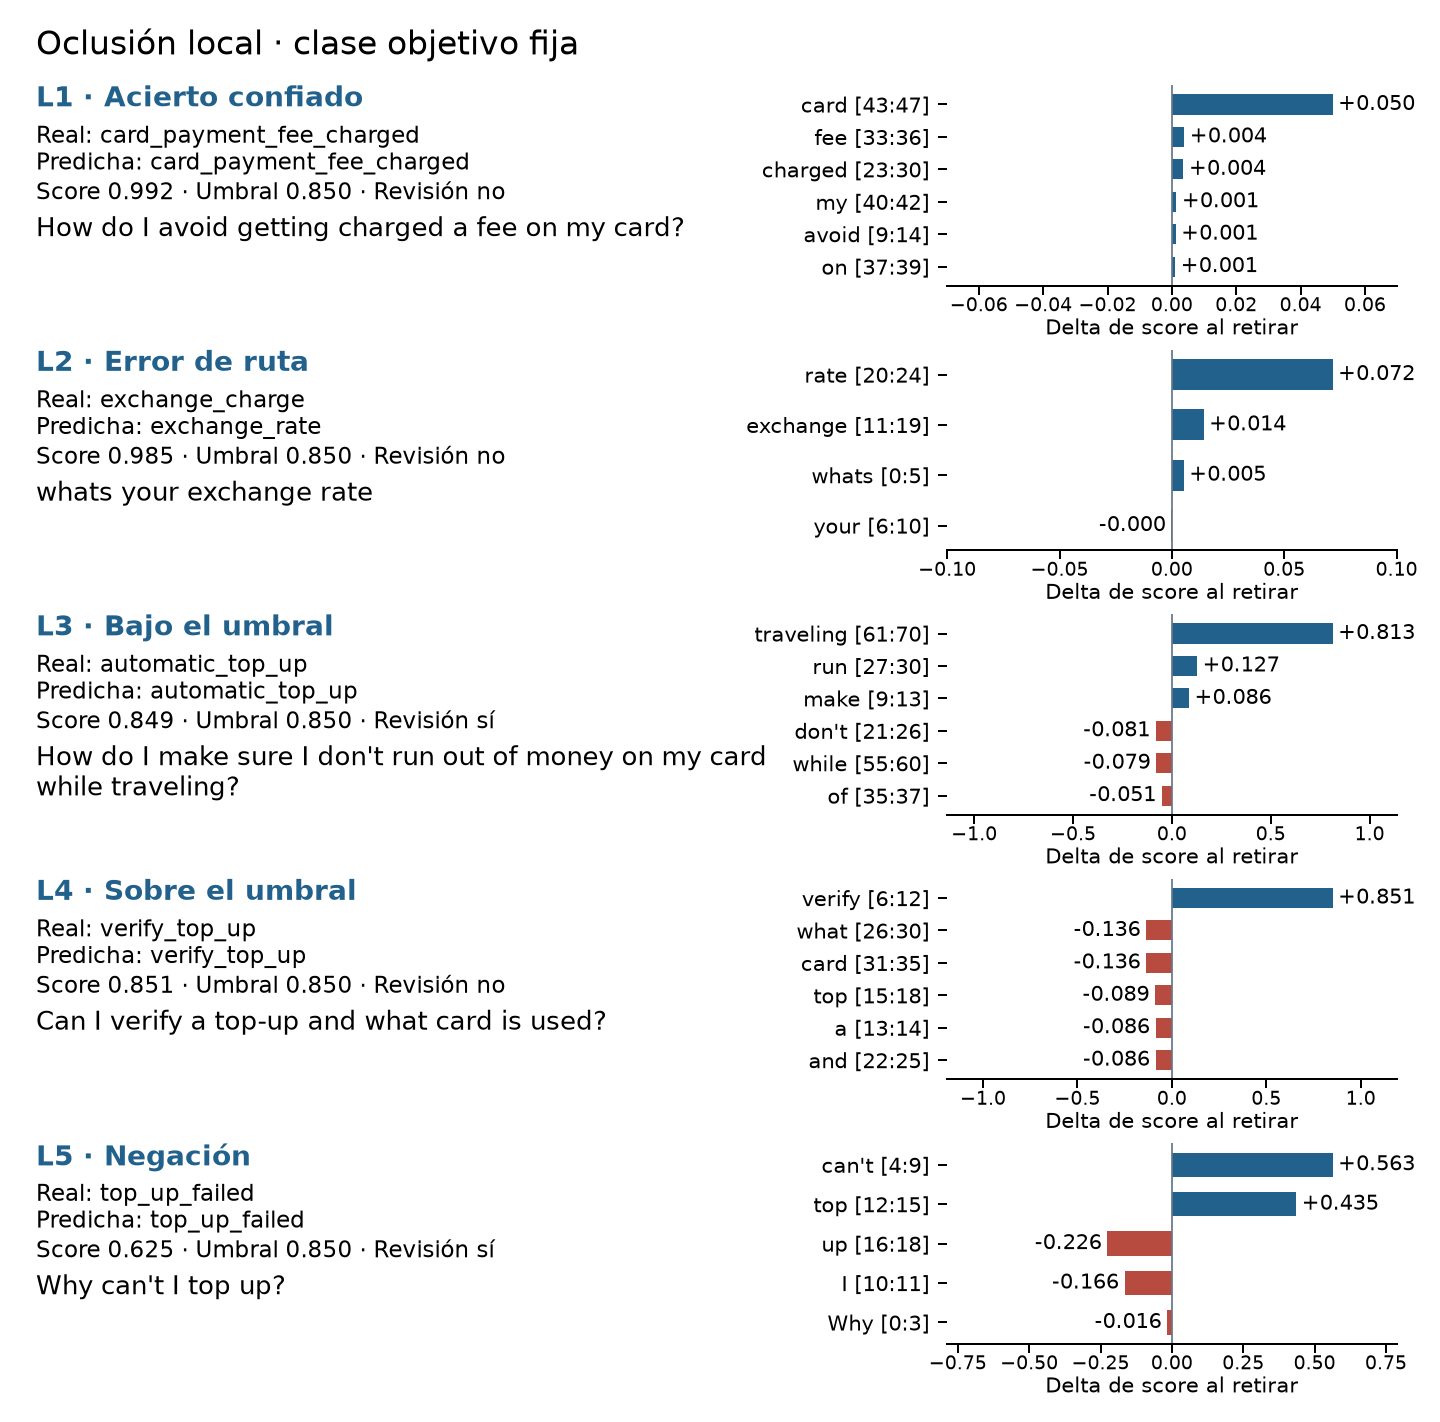

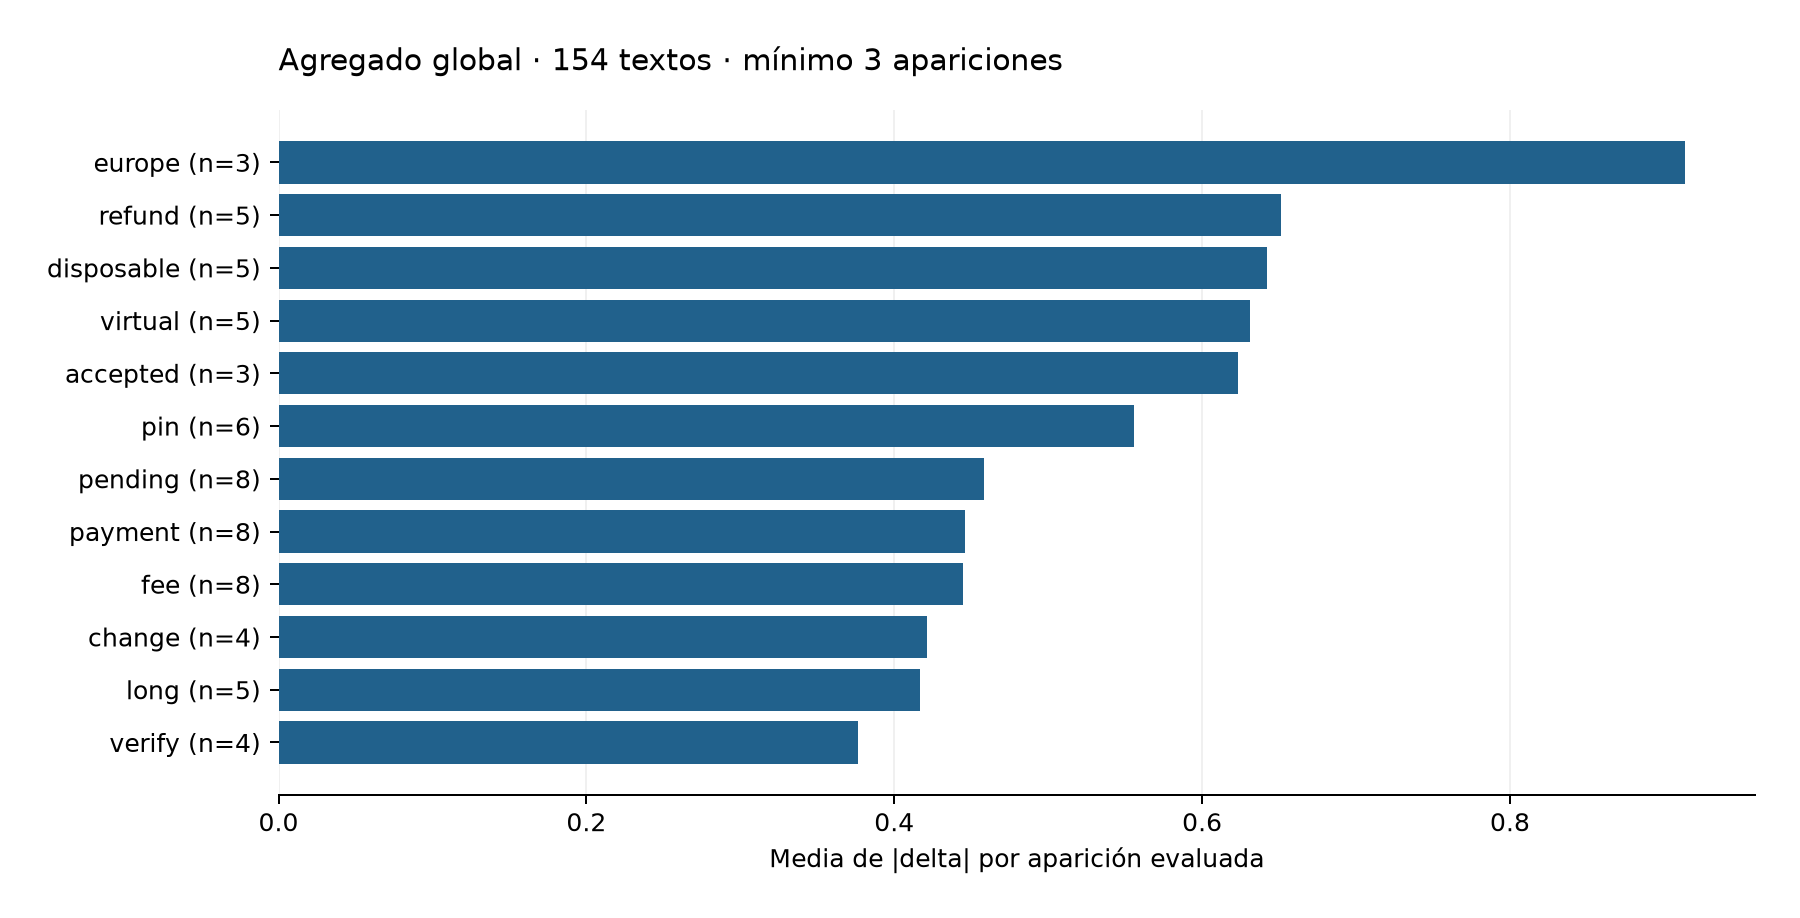

Palabra normalizada,Apariciones,Media |delta|,Media delta con signo
europe,3,0.913503,+0.913503
refund,5,0.650984,+0.650984
disposable,5,0.642357,+0.640793
virtual,5,0.630859,+0.630859
accepted,3,0.623394,+0.622878
pin,6,0.555622,+0.555243
pending,8,0.458403,+0.457632
payment,8,0.446052,+0.440622
fee,8,0.444597,+0.444597
change,4,0.421296,+0.421296


Figuras regeneradas: locales.png, locales.svg, global.png, global.svg


In [6]:
from lab10.render import render_results

RENDER_DIR = ROOT / "data" / "cache" / ("xai-notebook-" + uuid.uuid4().hex)
assert not RENDER_DIR.exists()
artifacts = render_results(RESULTS_PATH, RENDER_DIR)
assert all(path.resolve().is_relative_to(RENDER_DIR.resolve()) for path in artifacts)
display(Image(filename=str(RENDER_DIR / "locales.png")))
display(Image(filename=str(RENDER_DIR / "global.png")))
top_global = sorted((w for w in results["global"]["words"] if w["count"] >= 3),
                    key=lambda w: (-w["mean_abs_delta"], w["word"]))[:12]
show_table(["Palabra normalizada", "Apariciones", "Media |delta|", "Media delta con signo"], [
    (w["word"], w["count"], f"{w['mean_abs_delta']:.6f}", f"{w['mean_signed_delta']:+.6f}")
    for w in top_global])
print("Figuras regeneradas:", ", ".join(path.name for path in artifacts))

## Interpretación de los resultados observados

Las siguientes descripciones se calculan desde los valores reales guardados, con las funciones definidas en las siguientes celdas. Identifican la aparición más influyente por caso, cambios de clase y posibilidad de recuperar la etiqueta real mediante una eliminación; no presuponen que esa edición conserve la intención. El ranking global señala sensibilidad de la clase predicha en una muestra balanceada, no una explicación causal ni la frecuencia de palabras en producción.

In [7]:
from lab10.render import _number, _strongest, _tokens

def _case_description(case):
    chosen = _strongest(case, 1)
    target = case.get("occlusion", {}).get("target_label", case.get("predicted_label"))
    base = f"{case.get('case_id', case.get('id', 'Caso'))}: {case.get('reason', 'selección registrada')}. "
    if chosen:
        token = chosen[0]
        base += (f"Mayor efecto absoluto: «{token['word']}» ({float(token['delta']):+.4f}); "
                 f"score de {target} tras retirarla: {_number(token.get('score_after'), 4)}. ")
    switches = [t for t in _tokens(case) if t.get("prediction_after") != case.get("predicted_label")]
    if switches:
        token = max(switches, key=lambda t: abs(t["delta"]))
        base += f"{len(switches)} retiradas cambian la clase ganadora; «{token['word']}» lleva a {token.get('prediction_after')}. "
    else:
        base += "Ninguna retirada registrada cambia la clase ganadora. "
    if case.get("true_label") == "exchange_charge" and case.get("predicted_label") == "exchange_rate":
        base += ("La consulta sobre «exchange rate» admite la predicción exchange_rate como lectura plausible; "
                 "revisar contexto y etiqueta exchange_charge antes de atribuir un fallo semántico indiscutible. ")
    return base

def _local_metric_insight(cases):
    examples = []
    for case in cases:
        tokens = {t["word"].lower(): t for t in _tokens(case)}
        if "traveling" in tokens:
            examples.append(f"{case.get('case_id')}: «traveling» tiene delta {tokens['traveling']['delta']:+.4f}, "
                            "una dependencia geográfica fuerte que merece contrastarse con paráfrasis")
        if "verify" in tokens:
            examples.append(f"{case.get('case_id')}: «verify» tiene delta {tokens['verify']['delta']:+.4f}, "
                            "coherente temáticamente con verificar una recarga")
    return (("; ".join(examples) + ". La accuracy no revela estas dependencias distintas entre casos.")
            if examples else "La accuracy agregada no muestra qué palabras sostienen cada predicción.")

def _global_description(glob):
    words = sorted((w for w in glob.get("words", []) if w["count"] >= 3),
                   key=lambda w: (-w["mean_abs_delta"], w["word"]))[:3]
    if not words:
        return "No hay palabras con tres apariciones para interpretar un ranking global."
    details = "; ".join(f"«{w['word']}»: media |delta|={w['mean_abs_delta']:.4f}, n={w['count']}"
                        for w in words)
    contextual = {
        "europe": "«europe» delimita una región y puede separar consultas de disponibilidad geográfica; conviene contrastar otras regiones",
        "refund": "«refund» nombra un reembolso, señal temática plausible para distinguir esa intención",
        "disposable": "«disposable» especifica un tipo de tarjeta y puede diferenciarlo de tarjetas virtuales generales",
        "virtual": "«virtual» especifica el tipo de tarjeta",
        "fee": "«fee» apunta a cargos o comisiones",
        "pin": "«pin» alude a credenciales de tarjeta",
    }
    interpretations = [contextual[w["word"].lower()] for w in words if w["word"].lower() in contextual]
    reading = (" Lectura contextual tentativa: " + "; ".join(interpretations) + ".") if interpretations else ""
    return ("Las tres mayores sensibilidades observadas son " + details + ". "
            "Estas palabras señalan dónde inspeccionar dependencia léxica: los términos bancarios pueden "
            "distinguir intenciones; palabras generales, pronombres o conectores pueden reflejar contexto, "
            "negación o plantillas. El ranking mezcla clases y no permite asignarles por sí solo una función "
            "causal ni declarar un atajo. Los conteos permiten valorar cuánto respaldo observacional tiene cada media."
            + reading)

def _error_description(cases):
    errors = [c for c in cases if not c.get("correct", True)]
    if not errors:
        return "No hay un caso local incorrecto registrado para buscar una retirada que recupere la etiqueta real."
    summaries = []
    for case in errors:
        recovering = [t for t in _tokens(case) if t.get("prediction_after") == case.get("true_label")]
        if recovering:
            words = ", ".join(f"«{t['word']}»" for t in recovering[:4])
            summaries.append(f"En {case.get('case_id', case.get('id'))}, retirar {words} recupera la etiqueta real {case.get('true_label')}.")
        else:
            summaries.append(f"En {case.get('case_id', case.get('id'))}, ninguna eliminación individual evaluada recupera la etiqueta real {case.get('true_label')}.")
    return (" ".join(summaries) + " Una edición que cambie la salida no garantiza preservar el significado ni corregir el sistema: exige inspección humana y validación en datos nuevos.")

for case in results["local_cases"]:
    print(_case_description(case), "\n")
print(_local_metric_insight(results["local_cases"]), "\n")
print(_global_description(results["global"]), "\n")
print(_error_description(results["local_cases"]))


L1: acierto_alta_confianza. Mayor efecto absoluto: «card» (+0.0499); score de card_payment_fee_charged tras retirarla: 0.9422. Ninguna retirada registrada cambia la clase ganadora.  

L2: error_de_ruta. Mayor efecto absoluto: «rate» (+0.0715); score de exchange_rate tras retirarla: 0.9133. Ninguna retirada registrada cambia la clase ganadora. La consulta sobre «exchange rate» admite la predicción exchange_rate como lectura plausible; revisar contexto y etiqueta exchange_charge antes de atribuir un fallo semántico indiscutible.  

L3: cercano_umbral_inferior. Mayor efecto absoluto: «traveling» (+0.8126); score de automatic_top_up tras retirarla: 0.0367. 1 retiradas cambian la clase ganadora; «traveling» lleva a wrong_amount_of_cash_received.  

L4: cercano_umbral_superior. Mayor efecto absoluto: «verify» (+0.8506); score de verify_top_up tras retirarla: 0.0002. 1 retiradas cambian la clase ganadora; «verify» lleva a supported_cards_and_currencies.  

L5: subgrupo_negacion. Mayor efecto 

## Discusión y decisiones de uso

La oclusión permite contrastar directamente original y edición mediante probabilidades calibradas; frente a LIME evita ajustar un sustituto y hace explícita cada aparición. LIME permite estudiar una vecindad más amplia con fidelidad aproximada, a costa de muestreo y ajuste. SHAP agrega una referencia y un juego de coaliciones; IG requiere gradientes y elegir embeddings de referencia. Ninguno garantiza por sí mismo explicaciones estables ante paráfrasis o corrección semántica.

Las métricas agregadas no muestran qué términos sostienen una decisión ni si una negación cambia la salida. Las cinco consultas y el ranking añaden diagnósticos concretos, pero no permiten declarar ausencia de atajos, sesgo o fuga. Un error confiado puede trasladar trabajo al destino equivocado, producir transferencias o retrabajo y afectar confianza; no se midieron satisfacción, reputación ni CSAT. La consulta etiquetada `exchange_charge` y predicha `exchange_rate` requiere revisar contexto y posible ambigüedad de anotación antes de tratarla como un fallo semántico indiscutible.

Mantendría el clasificador y la política congelados y usaría la explicación bajo demanda o en auditorías por lotes, con revisión humana de la consulta completa. No adoptaría cambios usando este test. Para investigar dependencias débiles se necesitan nuevas paráfrasis que preserven significado, contrastes por intención y examen de duplicados/metadata en las particiones. Una retirada que cambia el ganador no ofrece recourse accionable; tampoco una etiqueta estable demuestra robustez.

Preferiría un modelo interpretable si alcanzara desempeño de rutas, calibración y costo comparables en validación independiente: sus coeficientes y contribuciones serían más fáciles de mantener. La presente auditoría no demuestra esa equivalencia. Como contexto histórico, el proyecto reporta TF-IDF con accuracy 87.85% y exactitud de ruta 95.84%, frente a V2 con accuracy 91.98% y exactitud de ruta 97.34%; no se recalcula el baseline aquí ni sus coeficientes explican DistilBERT.

La muestra global estratificada da igual cuota a cada clase; sus medias absolutas mezclan contextos y pierden dirección. Los conteos son apariciones y no documentos independientes: con solo tres observaciones un término puede tener poca estabilidad. No se presentan intervalos de confianza ni extrapolaciones poblacionales. Los tiempos observados separan carga, test y explicaciones; la referencia histórica de inferencia no permite obtener un factor de sobrecosto universal.

El corpus es BANKING77 de PolyAI, público, en inglés y bajo CC BY 4.0. Las eliminaciones son modificaciones analíticas de los ejemplos atribuidos. Estos resultados no se trasladan automáticamente a español, errores ortográficos, lenguaje mixto, grupos demográficos o reclamos operativos. En futuros textos reales, tablas y figuras también podrían revelar información personal: anonimizar y limitar acceso antes de compartir. La lectura humana debe evitar confianza excesiva en colores, barras o scores altos.

### Fuentes adicionales y trazabilidad

Las referencias primarias de LIME, SHAP, IG, APIs y baseline figuran en la investigación inicial. La implementación de oclusión se contrasta conceptualmente con [Captum: Occlusion](https://captum.ai/api/occlusion.html); este análisis ejecuta la oclusión de palabras propia del repositorio, no Captum. La procedencia del corpus se documenta en [PolyAI BANKING77](https://huggingface.co/datasets/PolyAI/banking77) y el protocolo del proyecto está en [ReclamoRuta](https://github.com/JosFer720/ReclamoRuta).

`results.json` conserva versión, temperatura, umbral, semilla, selección, hashes, entorno y tiempos. Las funciones de `lab10.run` conservan el scorer congelado; `lab10.render` reconstruye las figuras desde mediciones. Este notebook concentra el informe y permite repetir su lectura y visualización con las mismas entradas verificadas.